Practical NO.10   
Name - Sakshi Vijaykumar Muthiyan  
Roll No. -  
Title -Data Visualization using matplotlib    
Problem Statement: Analyzing Air Quality Index (AQI) Trends in a City    
Dataset: "City_Air_Quality.csv"     
Description: The dataset contains information about air quality measurements in a 
specific city over a period of time. It includes attributes such as date, time, pollutant 
levels (e.g., PM2.5, PM10, CO), and the Air Quality Index (AQI) values. The goal is to 
use the matplotlib library to create visualizations that effectively represent the AQI trends 
and patterns for different pollutants in the city.   

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore') 
# settings file paths for both datasets on desktop
path_pollutants = r"C:\Users\muthi\OneDrive\Desktop\PRACTICAL EXAM\DMV\archive (7)\pune_pollutants.csv"
path_aqi = r"C:\Users\muthi\OneDrive\Desktop\PRACTICAL EXAM\DMV\archive (7)\pune_aqi.csv"
print("Loading original Pune air quality datasets...")
df_p = pd.read_csv(path_pollutants)
df_a = pd.read_csv(path_aqi)
# task 1 & 3: cleaning headers and merging datasets on common Date key column
df_p.columns = df_p.columns.str.strip()
df_a.columns = df_a.columns.str.strip()
# merging both datasets to get all pollutants and aqi metrics together
df_aqi = pd.merge(df_p, df_a[['Date', 'AQI']], on='Date', how='inner')
print("\n=== Task 2: Merged Dataset Matrix Shape ===")
print("Dimensions Data Shape:", df_aqi.shape)
df_aqi[['Date', 'PM2.5', 'PM10', 'CO', 'AQI']].head(3)

Loading original Pune air quality datasets...

=== Task 2: Merged Dataset Matrix Shape ===
Dimensions Data Shape: (8010, 10)


,Date,PM2.5,PM10,CO,AQI
0,2023-12-31,211.0,191.0,59.0,145.0
1,2023-12-31,225.0,185.0,62.0,145.0
2,2023-12-31,240.0,182.0,50.0,145.0


=== Task 3: Visualizing Variables Extracted ===
X-Axis DataType Timeline Component: datetime64[ns]
Y-Axis Target Pollutant Streams Array: ['AQI', 'PM2.5', 'PM10', 'CO']


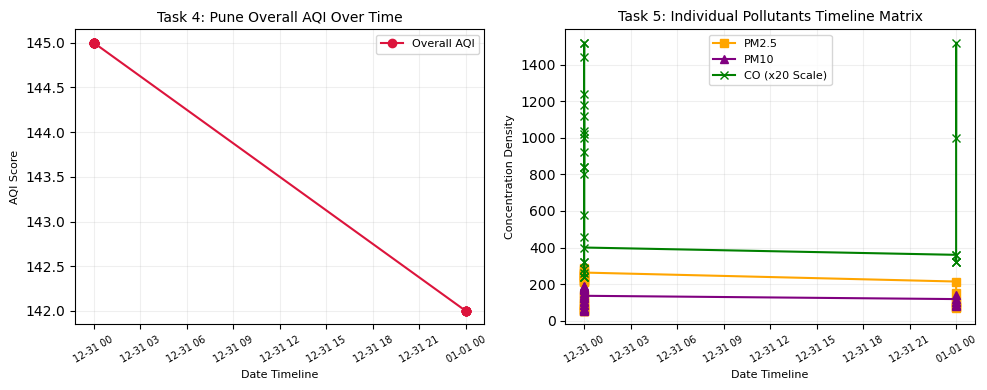

In [17]:
# task 3: explicitly identify columns relevant to plotting tasks
print("=== Task 3: Visualizing Variables Extracted ===")
print("X-Axis DataType Timeline Component:", df_aqi['Date'].dtype)
print("Y-Axis Target Pollutant Streams Array:", ['AQI', 'PM2.5', 'PM10', 'CO'])
# sorting rows sequence and slicing top 30 rows to prevent data overflow
df_sorted = df_aqi.sort_values('Date').head(30)
# Creating a 10x4 layout grid for side-by-side subplots configuration
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
# --- Left Chart: Task 4 Overall AQI Trend ---
axes[0].plot(df_sorted['Date'], df_sorted['AQI'], marker='o', color='crimson', linewidth=1.5, label='Overall AQI')
axes[0].set_title('Task 4: Pune Overall AQI Over Time', fontsize=10)
axes[0].set_xlabel('Date Timeline', fontsize=8)
axes[0].set_ylabel('AQI Score', fontsize=8)
axes[0].tick_params(axis='x', rotation=30, labelsize=7)
axes[0].grid(True, alpha=0.2)
axes[0].legend(fontsize=8)
# --- Right Chart: Task 5 Individual Pollutants Level Trend ---
axes[1].plot(df_sorted['Date'], df_sorted['PM2.5'], marker='s', color='orange', label='PM2.5')
axes[1].plot(df_sorted['Date'], df_sorted['PM10'], marker='^', color='purple', label='PM10')
axes[1].plot(df_sorted['Date'], df_sorted['CO'] * 20, marker='x', color='green', label='CO (x20 Scale)') 
axes[1].set_title('Task 5: Individual Pollutants Timeline Matrix', fontsize=10)
axes[1].set_xlabel('Date Timeline', fontsize=8)
axes[1].set_ylabel('Concentration Density', fontsize=8)
axes[1].tick_params(axis='x', rotation=30, labelsize=7)
axes[1].grid(True, alpha=0.2)
axes[1].legend(fontsize=8)
# layout adjustment block to trim blank padding margins away from pages
plt.tight_layout()
plt.show()

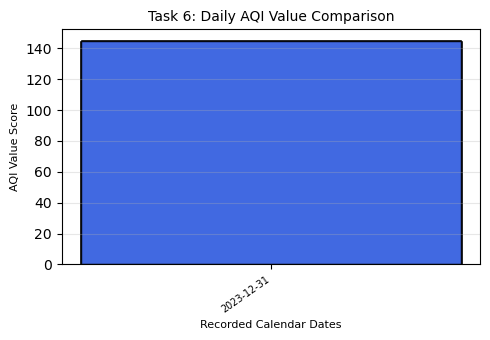

In [18]:
# task 6: vertical bar plot comparing values across different dates snapshot
plt.figure(figsize=(5, 3.5))
bar_sample = df_sorted.head(10) # 10 records snapshot to keep graph bars distinct and clean
date_labels = bar_sample['Date'].dt.strftime('%Y-%m-%d')
plt.bar(date_labels, bar_sample['AQI'], color='royalblue', edgecolor='black', alpha=0.85)
plt.title('Task 6: Daily AQI Value Comparison', fontsize=10)
plt.xlabel('Recorded Calendar Dates', fontsize=8)
plt.ylabel('AQI Value Score', fontsize=8)
plt.xticks(rotation=35, ha='right', fontsize=7)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

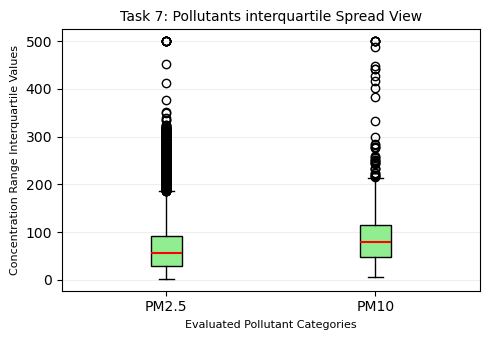

In [19]:
# task 7: box plots to analyze pollutant metrics distributions density spread
plt.figure(figsize=(5, 3.5))
distribution_list = [df_aqi['PM2.5'], df_aqi['PM10']]
plt.boxplot(distribution_list, labels=['PM2.5', 'PM10'], patch_artist=True, 
            boxprops=dict(facecolor='lightgreen', color='black'),
            medianprops=dict(color='red', linewidth=1.5))
plt.title('Task 7: Pollutants interquartile Spread View', fontsize=10)
plt.xlabel('Evaluated Pollutant Categories', fontsize=8)
plt.ylabel('Concentration Range Interquartile Values', fontsize=8)
plt.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.show()

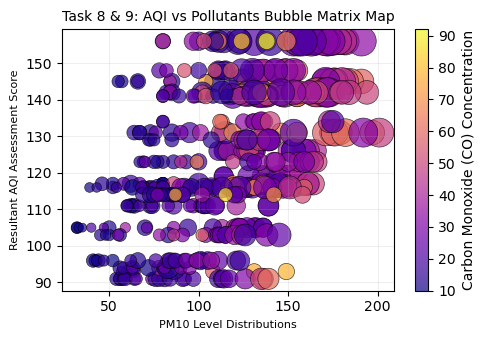

In [20]:
# task 8 & 9: scatter bubble charts with full styling custom additions
plt.figure(figsize=(5, 3.5))
bubble_size = df_aqi['PM2.5'].head(500) * 1.5 # bubble scaling density limits
scatter_plot = plt.scatter(df_aqi['PM10'].head(500), df_aqi['AQI'].head(500), s=bubble_size, c=df_aqi['CO'].head(500), 
                          cmap='plasma', alpha=0.7, edgecolor='black', linewidth=0.5)
# task 9 advanced labels and color schema decorations additions
plt.title('Task 8 & 9: AQI vs Pollutants Bubble Matrix Map', fontsize=10)
plt.xlabel('PM10 Level Distributions', fontsize=8)
plt.ylabel('Resultant AQI Assessment Score', fontsize=8)
plt.colorbar(scatter_plot, label='Carbon Monoxide (CO) Concentration')
plt.grid(True, alpha=0.2)
plt.tight_layout() # trims padding borders to minimize sheet printing counts
plt.show()